# Motivation 2: the long-term state is hidden from the BMS and drifts over the service life

**Message.** (a) A BMS counts charge against the *rated* capacity, so on an aged pack it reports more
charge than is left: an SOH-unaware controller ends below the SOC reserve while the BMS still shows the
reserve intact. (b) Over the robot's service life, the energy budget an SOH-unaware planner assumes is
wrong by far more than the speed/DVFS decision can recover, early in life already. The long-term state
must therefore be estimated on-line.

**Setting** (benchmark `degradation` family, C = 2, 5 km, same initial SOC for every SOH), BMS
observations with battery realism (sensor noise, gain error, cell variation) exactly as in the
benchmark (`evaluation/benchmark.py`).

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().resolve()
while not (REPO / 'envs').is_dir() and REPO != REPO.parent:   # notebook lives in <repo>/figures
    REPO = REPO.parent
sys.path.insert(0, str(REPO))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import envs  # noqa: F401  (sys.path for battery_model)
from envs.robot_env import RobotEnv, ECMParams, StressParams, throughput_freq_required, _voc
from envs.scenarios import build_suite, make_env
from methods import BatteryAwareEPD, LagRLSEPD
from evaluation.metrics import run_episode
from envs.test_env import EVAL_CONFIG, make_robot

OUT = REPO / 'figures' / 'pdf'
OUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'font.family': 'serif', 'font.serif': ['Times New Roman', 'STIXGeneral', 'DejaVu Serif'],
    'mathtext.fontset': 'stix', 'font.size': 8, 'axes.titlesize': 8, 'axes.labelsize': 8,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 7.5,
    'axes.grid': True, 'grid.linestyle': '--', 'grid.linewidth': 0.4, 'grid.color': '#c8c8c8',
    'pdf.fonttype': 42, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02,
})

## Settings

In [2]:
C = 2.0
L = 5000.0
BMS = dict(EVAL_CONFIG, battery_obs='bms', battery_realism=True)
SUITE = [sc for sc in build_suite(['degradation']) if sc.tags['c'] == C]
SOC0 = SUITE[0].soc0
SOH_TRACE, TRACE_SEED = 0.8, 3                 # the trajectory example of the paper
QOS_MARGIN = EVAL_CONFIG['baseline_qos_margin']
JITTER = EVAL_CONFIG['test_complexity_jitter']
rp = make_robot(EVAL_CONFIG)
print(f'C = {C:g}, initial SOC {SOC0:.4f}, {len(SUITE)} SOH levels')

C = 2, initial SOC 0.1925, 9 SOH levels


## (a) SOH-unaware mission on an aged pack: BMS SOC vs. true SOC

In [3]:
sc = next(s for s in SUITE if np.isclose(s.soh, SOH_TRACE))
env = make_env(BMS, sc)
pol = BatteryAwareEPD(make_robot(BMS), BMS)                  # SOC-aware, assumes SOH = 1
obs, _ = env.reset(seed=BMS['seed'] + TRACE_SEED, options=sc.options())
pol.reset()
trace, done = [], False
while not done:
    a = pol.select_action(obs)
    soc_bms = float(obs[2])
    obs, _, term, trunc, info = env.step(a)
    done = term or trunc
    trace.append(dict(t=info['t_s'], v=float(a[0]), soc_bms=soc_bms, soc_true=info['soc']))
trace = pd.DataFrame(trace)
print(f"median speed {trace.v.median():.2f} m/s | end: BMS {trace.soc_bms.iloc[-1]:.3f}, true {trace.soc_true.iloc[-1]:.3f}")

median speed 3.90 m/s | end: BMS 0.072, true 0.043


## (b) Budget error of an SOH-unaware planner over the service life

In [4]:
def budget(soc0, soh):
    """Cell-side energy above the reserve [J] (env accounting: Q_n * SOH * integral OCV dSOC)."""
    s = np.linspace(rp.soc_reserve, soc0, 400)
    return np.trapezoid([_voc(x, soh) for x in s], s) * rp.Q_n * soh


def mission_energy(v, soh=1.0, seed=0):
    """Energy [J] of the 5 km mission at constant speed v and the controllers' QoS frequency."""
    r = make_robot(dict(EVAL_CONFIG, mission_distance_m=L))
    r.max_steps = 10**6
    f_req = throughput_freq_required(v, QOS_MARGIN * max(r.qos_ref), (1 + JITTER) * C)
    if f_req > r.f_max + 1e-12:
        return np.nan
    f = float(np.clip(f_req, r.f_min, r.f_max))
    e = RobotEnv(robot=r, ecm=ECMParams.default(r), stress=StressParams(), soc_init=0.9, soh_init=soh,
                 complexity=C, mode='test', complexity_jitter=JITTER)
    e.reset(seed=seed)
    d = False
    while not d:
        _, _, te, tr, _ = e.step([v, f])
        d = te or tr
    return e.total_energy_j


# what the speed/DVFS decision can trade: slowing from the reward-optimal speed to the energy optimum
V = np.round(np.arange(1.5, 5.0 + 1e-9, 0.05), 3)
E = np.array([mission_energy(float(v)) for v in V])
cost = rp.w_energy * E / L + rp.w_time * rp.v_ref_mps / V          # per-mission energy + time terms
v_free, v_emin = V[np.nanargmin(cost)], V[np.nanargmin(E)]
e_min, e_free = np.nanmin(E), E[np.nanargmin(cost)]
trade = 100 * (e_free - e_min) / e_min

# ageing per mission (Xu model, Lag-RLS driving) -> distance driven vs SOH
fd = []
for s in SUITE:
    m = run_episode(make_env(BMS, s), LagRLSEPD(make_robot(BMS), BMS), seed=BMS['seed'],
                    charge_c_rate=BMS['charge_c_rate'], options=s.options())
    fd.append((s.soh, m['fd_cycle']))
fd = pd.DataFrame(fd, columns=['soh', 'fd_cycle']).sort_values('soh')
F = np.linspace(0.0, -np.log(rp.SOH_EOL), 201)                      # SOH = exp(-F)
fd_g = np.interp(np.exp(-F), fd.soh, fd.fd_cycle)
km = L / 1e3 * np.concatenate([[0.0], np.cumsum(0.5 * (1 / fd_g[1:] + 1 / fd_g[:-1]) * np.diff(F))]) / 1e3
soh_life = np.exp(-F)
over = 100 * np.array([budget(SOC0, 1.0) - budget(SOC0, h) for h in soh_life]) / e_min
k = int(np.argmax(over >= trade))
print(f'reward-optimal {v_free:.2f} m/s, energy-optimal {v_emin:.2f} m/s -> trade {trade:.1f} % of mission energy')
print(f'over-estimate exceeds it after {km[k]:.2f}e3 km (SOH {soh_life[k]:.3f}); {over[-1]:.1f} % at EOL ({km[-1]:.1f}e3 km)')

reward-optimal 3.60 m/s, energy-optimal 3.00 m/s -> trade 2.2 % of mission energy
over-estimate exceeds it after 2.73e3 km (SOH 0.985); 28.0 % at EOL (36.0e3 km)


## Figure

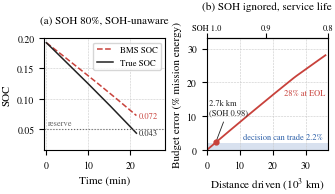

In [5]:
RED, BLUE, INK, GREY = '#c8413b', '#2a5ea8', '#222222', '#666666'
fig, axes = plt.subplots(1, 2, figsize=(3.6, 2.15))

ax = axes[0]
t = trace.t / 60
ax.plot(t, trace.soc_bms, color=RED, ls='--', lw=1.1, label='BMS SOC')
ax.plot(t, trace.soc_true, color=INK, lw=1.1, label='True SOC')
ax.axhline(rp.soc_reserve, color=GREY, ls=':', lw=0.8)
ax.text(0.5, rp.soc_reserve + 0.003, 'reserve', fontsize=6, color=GREY, va='bottom')
te = t.iloc[-1]
ax.text(te + 0.6, trace.soc_bms.iloc[-1], f'{trace.soc_bms.iloc[-1]:.3f}', fontsize=6, color=RED, va='center')
ax.text(te + 0.6, trace.soc_true.iloc[-1], f'{trace.soc_true.iloc[-1]:.3f}', fontsize=6, color=INK, va='center')
ax.set_xlim(-0.5, te * 1.32)
ax.set_ylim(0.015, 0.2)
ax.set_xlabel('Time (min)')
ax.set_ylabel('SOC')
ax.set_title('(a) SOH 80%, SOH-unaware', pad=11)
ax.legend(loc='upper right', fontsize=6.3, handlelength=1.8)

ax = axes[1]
ax.axhspan(0, trade, color=BLUE, alpha=0.18, lw=0)
ax.text(km[-1] * 0.98, trade + 0.6, f'decision can trade {trade:.1f}%', fontsize=6, color=BLUE, ha='right',
        va='bottom')
ax.plot(km, over, color=RED, lw=1.3, label='budget error')
ax.plot([km[k]], [over[k]], marker='o', color=RED, ms=3.5, zorder=5)
ax.annotate(f'{km[k]:.1f}k km\n(SOH {soh_life[k]:.2f})', (km[k], over[k]), xytext=(0.8, 10.5),
            fontsize=6, color=INK, arrowprops=dict(arrowstyle='-', color=INK, lw=0.6))
ax.text(km[-1], over[-1] - 10, f'{over[-1]:.0f}% at EOL', fontsize=6, color=RED, ha='right', va='top')
ax.set_xlim(0, km[-1] * 1.02)
ax.set_ylim(0, over[-1] * 1.18)
ax.set_xlabel('Distance driven (10$^3$ km)')
ax.set_ylabel('Budget error (% mission energy)')
ax.set_title('(b) SOH ignored, service life', pad=11)
top = ax.secondary_xaxis('top', functions=(lambda x: np.interp(x, km, soh_life),
                                           lambda y: np.interp(-np.asarray(y), -soh_life, km)))
top.set_xticks([1.0, 0.9, 0.8])
top.set_xticklabels(['SOH 1.0', '0.9', '0.8'])
top.tick_params(labelsize=6, pad=1)
fig.tight_layout(w_pad=0.6)
fig.savefig(OUT / 'motivation_2.pdf')
plt.show()

**Caption draft.** *Fig. 2. (a) A SOC-aware but SOH-unaware controller on an aged pack (SOH 0.8): the BMS,
counting charge against the rated capacity, reports the reserve intact while the true SOC ends below it.
(b) Over the service life (repeated 5 km missions, Xu ageing), the energy-budget error from ignoring SOH
exceeds the energy the speed/DVFS decision can trade (slowing from the reward-optimal to the
energy-optimal configuration) early in life and reaches about a quarter of the mission energy at end of
life.*